In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [55]:
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 5)

In [56]:
df = pd.read_excel(
    r"C:\Users\annap\Desktop\dataset_set_D_telecomunicaciones.xlsx"
)

df.head()

,fecha_registro,region,tipo_servicio,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados,cumplimiento_sla
0,2025-03-01,Centro,Empresas,457.8,21.3,0,27,22.4,144,No cumple
1,2025-03-02,Norte,Internet Hogar,383.4,36.5,13,19,39.4,290,No cumple
2,2025-03-03,Norte,Empresas,457.3,97.4,7,15,1.7,427,Cumple
3,2025-03-04,Norte,Móvil,62.5,119.4,12,30,38.2,116,Cumple
4,2025-03-05,Norte,Empresas,356.1,111.0,9,30,21.5,389,No cumple


In [57]:
df.shape

(200, 10)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fecha_registro          200 non-null    datetime64[ns]
 1   region                  200 non-null    object        
 2   tipo_servicio           200 non-null    object        
 3   trafico_datos_gb        200 non-null    float64       
 4   latencia_ms             200 non-null    float64       
 5   incidencias_reportadas  200 non-null    int64         
 6   tickets_soporte         200 non-null    int64         
 7   tiempo_resolucion_hr    200 non-null    float64       
 8   clientes_afectados      200 non-null    int64         
 9   cumplimiento_sla        200 non-null    object        
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 15.8+ KB


In [59]:
df.isnull().sum()

fecha_registro            0
region                    0
tipo_servicio             0
trafico_datos_gb          0
latencia_ms               0
incidencias_reportadas    0
tickets_soporte           0
tiempo_resolucion_hr      0
clientes_afectados        0
cumplimiento_sla          0
dtype: int64

In [60]:
df.describe()

,fecha_registro,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados
count,200,200.000000,200.000000,200.000000,200.000000,200.00000,200.00000
mean,2025-06-08 12:00:00,287.229000,64.861500,13.545000,31.390000,25.32950,265.37500
min,2025-03-01 00:00:00,50.500000,11.200000,0.000000,5.000000,1.20000,10.00000
25%,2025-04-19 18:00:00,181.825000,36.875000,6.000000,18.750000,12.70000,146.50000
50%,2025-06-08 12:00:00,289.100000,64.900000,14.000000,31.000000,26.35000,281.50000
75%,2025-07-28 06:00:00,398.750000,91.725000,20.000000,44.000000,37.72500,376.00000
max,2025-09-16 00:00:00,497.900000,119.900000,29.000000,59.000000,47.20000,499.00000
std,NaN,130.551383,32.907065,8.423345,15.521679,13.67296,139.99316


In [61]:
print(df.columns.tolist())
print(df.shape)

['fecha_registro', 'region', 'tipo_servicio', 'trafico_datos_gb', 'latencia_ms', 'incidencias_reportadas', 'tickets_soporte', 'tiempo_resolucion_hr', 'clientes_afectados', 'cumplimiento_sla']
(200, 10)


In [62]:
df_filtrado = df.copy()

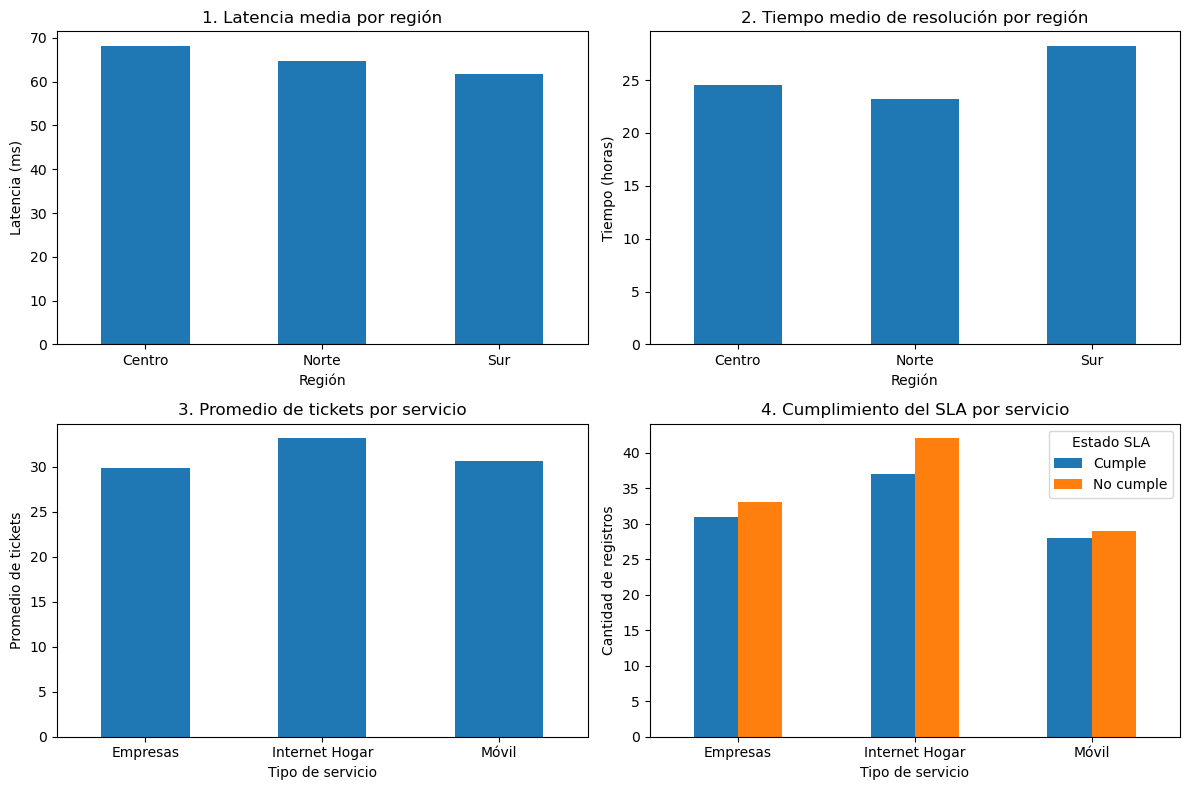

In [63]:
df_filtrado = df.copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# GRÁFICO 1: Latencia media por región
datos = df_filtrado.groupby("region")["latencia_ms"].mean()

datos.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("1. Latencia media por región")
axes[0, 0].set_xlabel("Región")
axes[0, 0].set_ylabel("Latencia (ms)")
axes[0, 0].tick_params(axis="x", rotation=0)

# GRÁFICO 2: Tiempo medio de resolución por región
datos = df_filtrado.groupby("region")["tiempo_resolucion_hr"].mean()

datos.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("2. Tiempo medio de resolución por región")
axes[0, 1].set_xlabel("Región")
axes[0, 1].set_ylabel("Tiempo (horas)")
axes[0, 1].tick_params(axis="x", rotation=0)

# GRÁFICO 3: Tickets de soporte por servicio
datos = df_filtrado.groupby("tipo_servicio")["tickets_soporte"].mean()

datos.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("3. Promedio de tickets por servicio")
axes[1, 0].set_xlabel("Tipo de servicio")
axes[1, 0].set_ylabel("Promedio de tickets")
axes[1, 0].tick_params(axis="x", rotation=0)

# GRÁFICO 4: Cumplimiento del SLA por servicio
tabla = pd.crosstab(
    df_filtrado["tipo_servicio"],
    df_filtrado["cumplimiento_sla"]
)

tabla.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("4. Cumplimiento del SLA por servicio")
axes[1, 1].set_xlabel("Tipo de servicio")
axes[1, 1].set_ylabel("Cantidad de registros")
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend(title="Estado SLA")

plt.tight_layout()
plt.show()


In [64]:


import pandas as pd

# Crear carpeta para los archivos de salida
os.makedirs("outputs", exist_ok=True)

# Archivo para Soporte Técnico
columnas_soporte = [
    "fecha_registro",
    "region",
    "tipo_servicio",
    "latencia_ms",
    "incidencias_reportadas",
    "tickets_soporte",
    "tiempo_resolucion_hr",
    "cumplimiento_sla"
]

df_soporte = df[columnas_soporte].copy()

df_soporte.to_csv(
    "outputs/reporte_soporte_tecnico.csv",
    index=False,
    encoding="utf-8-sig"
)

# Archivo para Experiencia de Clientes
columnas_clientes = [
    "fecha_registro",
    "region",
    "tipo_servicio",
    "clientes_afectados",
    "tickets_soporte",
    "tiempo_resolucion_hr",
    "cumplimiento_sla"
]

df_clientes = df[columnas_clientes].copy()

df_clientes.to_csv(
    "outputs/reporte_experiencia_clientes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos generados correctamente.")


Archivos generados correctamente.
